# Coding Theory Visual Lab
## From Reliable Communication to Security-Aware System Design

**A computational companion to Chapter 1 of _Error Control Coding_.**

This notebook turns the chapter's core concepts into reproducible experiments:

- binary block codes, code rate, Hamming geometry and syndrome-based detection;
- maximum-likelihood (ML) and maximum-a-posteriori (MAP) decoding over a BSC;
- binary erasure channel (BEC), BPSK modulation and AWGN;
- BER/WER, Monte Carlo verification, coding gain and BPSK-constrained Shannon limit;
- random versus burst errors, interleaving and an idealized ARQ comparison;
- a security case study showing why error correction is not cryptographic integrity.

### Central case study

\[
\mathcal{C}=\{000,111\},\qquad (n,k)=(3,1),\qquad R=k/n=1/3.
\]

The repetition code is deliberately small: all possible received words can be enumerated, visualized and explained exactly.

> **Important distinction:** channel coding improves reliability against a specified noise model. It does not authenticate a sender, prevent intentional modification, or provide confidentiality. The final security experiment makes this distinction concrete.

**Runtime:** Google Colab or Jupyter · Python · NumPy · SciPy · Matplotlib.  
No paid API, GPU or external dataset is required.

## 0. Experimental setup and conventions

We use:
- \(0\mapsto +\sqrt{E_s}\) and \(1\mapsto-\sqrt{E_s}\) for BPSK;
- real AWGN with variance \(N_0/2\) per received symbol;
- \(E_b\) as energy per **information bit**, hence \(E_s=R E_b\);
- equally likely information bits except in the MAP-prior demonstration;
- independent bit flips for the BSC, unless the Gilbert–Elliott experiment explicitly introduces memory.

This normalization matters. Comparing coded and uncoded systems at the same \(E_s/N_0\) is not the same as comparing them at the same \(E_b/N_0\).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from scipy.special import erfc
from scipy.optimize import brentq
from itertools import product
from IPython.display import display
import hashlib
import hmac

SEED = 2026
rng = np.random.default_rng(SEED)

# Consistent visual identity
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 220,
    "font.size": 10.5, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22,
    "legend.frameon": False, "lines.linewidth": 2.4,
    "figure.max_open_warning": 50,
})
NAVY, BLUE, TEAL = "#17324D", "#2878B5", "#1B998B"
ORANGE, RED, PURPLE = "#E07A2D", "#C44536", "#7057A3"
GRAY, LIGHT = "#68737D", "#EAF0F4"

# Binary (3,1) repetition code
CODEWORDS = np.array([[0, 0, 0], [1, 1, 1]], dtype=np.int8)
G = np.array([[1, 1, 1]], dtype=np.int8)
H = np.array([[1, 1, 0], [0, 1, 1]], dtype=np.int8)

N, K = 3, 1
R = K / N
D_MIN = int(np.sum(CODEWORDS[0] != CODEWORDS[1]))
T_CORRECT = (D_MIN - 1) // 2
T_DETECT = D_MIN - 1
ALL_WORDS = np.array(list(product([0, 1], repeat=N)), dtype=np.int8)
VALID_SET = {tuple(x) for x in CODEWORDS}

print("Code C = {000, 111}")
print(f"(n, k) = ({N}, {K}) | code rate R = {R:.6f}")
print(f"d_min = {D_MIN} | guaranteed correction t = {T_CORRECT}")
print(f"Guaranteed detection = up to {T_DETECT} errors")

Code C = {000, 111}
(n, k) = (3, 1) | code rate R = 0.333333
d_min = 3 | guaranteed correction t = 1
Guaranteed detection = up to 2 errors


## 1. System model: where coding fits

The source produces information bits \(u\). The encoder maps them to a longer codeword \(v\). Modulation maps code symbols to waveforms, the noisy channel corrupts them, and the receiver makes observations that are passed to a decoder.

This is **forward error correction (FEC)**: the receiver attempts to correct errors without requesting retransmission.

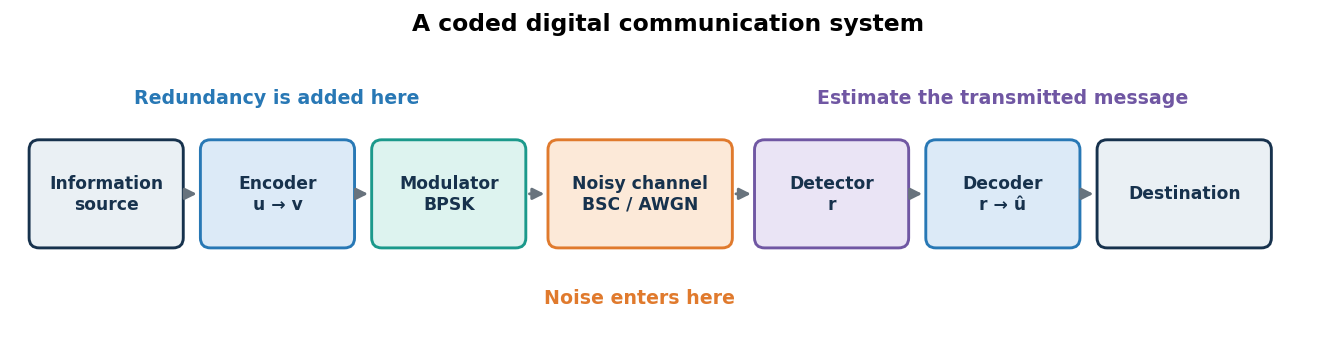

In [2]:
def draw_system_model():
    fig, ax = plt.subplots(figsize=(13, 3.0))
    ax.set_xlim(0, 13); ax.set_ylim(0, 3); ax.axis("off")
    boxes = [
        (0.20, 1.05, 1.45, 1.0, "Information\nsource", LIGHT, NAVY),
        (1.90, 1.05, 1.45, 1.0, "Encoder\nu → v", "#DCEAF7", BLUE),
        (3.60, 1.05, 1.45, 1.0, "Modulator\nBPSK", "#DDF3EF", TEAL),
        (5.35, 1.05, 1.75, 1.0, "Noisy channel\nBSC / AWGN", "#FCE9D8", ORANGE),
        (7.40, 1.05, 1.45, 1.0, "Detector\nr", "#EAE4F5", PURPLE),
        (9.10, 1.05, 1.45, 1.0, "Decoder\nr → û", "#DCEAF7", BLUE),
        (10.80, 1.05, 1.65, 1.0, "Destination", LIGHT, NAVY),
    ]
    edges = []
    for x, y, w, h, label, face, edge in boxes:
        ax.add_patch(FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.10",
            linewidth=1.6, edgecolor=edge, facecolor=face))
        ax.text(x+w/2, y+h/2, label, ha="center", va="center",
                color=NAVY, fontsize=9.5, weight="bold")
        edges.append((x, x+w))
    for i in range(len(edges)-1):
        ax.add_patch(FancyArrowPatch((edges[i][1]+0.04, 1.55),
                      (edges[i+1][0]-0.04, 1.55),
                      arrowstyle="-|>", mutation_scale=13,
                      color=GRAY, linewidth=1.6))
    ax.text(2.62, 2.45, "Redundancy is added here",
            ha="center", color=BLUE, weight="bold")
    ax.text(6.22, 0.45, "Noise enters here",
            ha="center", color=ORANGE, weight="bold")
    ax.text(9.82, 2.45, "Estimate the transmitted message",
            ha="center", color=PURPLE, weight="bold")
    ax.set_title("A coded digital communication system", pad=10)
    plt.show()

draw_system_model()

## 2. Code structure and Hamming geometry

A binary \((n,k)\) block code maps \(2^k\) messages to codewords of length \(n\). Its rate is \(R=k/n\). The Hamming distance counts the number of positions at which two binary vectors differ.

For this code:
\[
d_{\min}=d(000,111)=3,\qquad
t=\left\lfloor\frac{d_{\min}-1}{2}\right\rfloor=1.
\]

The eight vertices of the 3-cube are all possible received words. The two valid codewords are separated by three bit flips. Radius-one Hamming balls around them do not overlap and cover the whole cube.

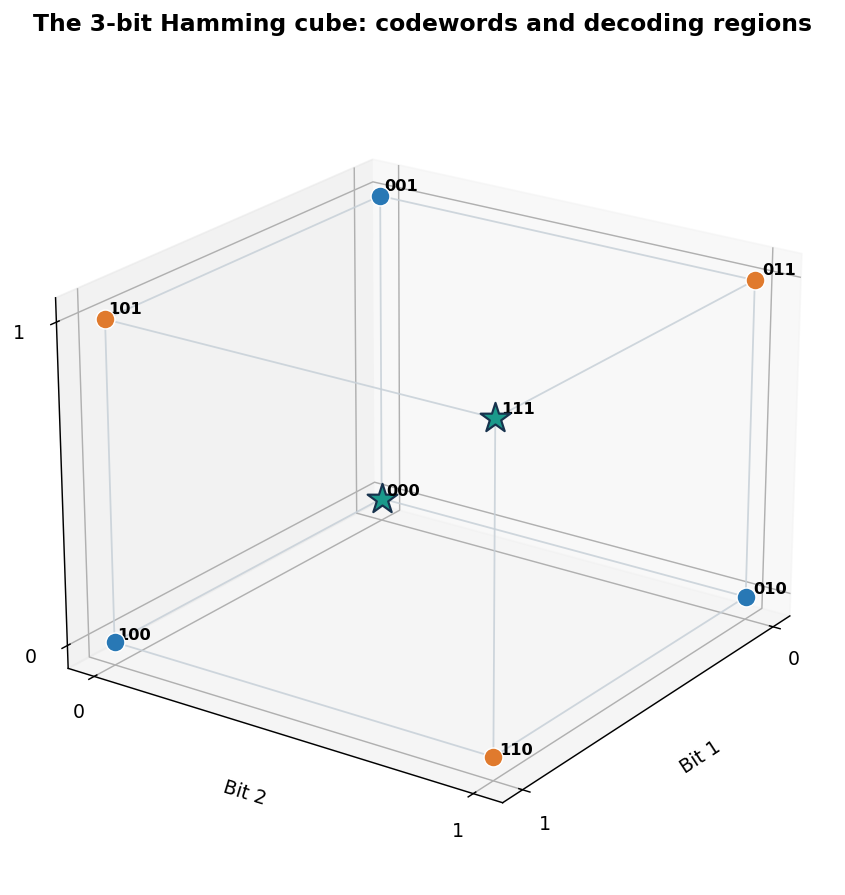

Generator matrix G = [[1, 1, 1]]
Parity-check matrix H =
 [[1 1 0]
 [0 1 1]]
H @ G.T mod 2 = [0, 0] (must be all zeros)


In [3]:
def hamming_distance(a, b):
    a = np.asarray(a, dtype=np.int8)
    b = np.asarray(b, dtype=np.int8)
    return int(np.sum(a != b))

def nearest_codeword(received):
    distances = np.array([hamming_distance(received, cw) for cw in CODEWORDS])
    idx = int(np.argmin(distances))
    return CODEWORDS[idx].copy(), distances

def encode_bit(bit):
    if bit not in (0, 1):
        raise ValueError("The input bit must be 0 or 1.")
    return np.repeat(np.int8(bit), N)

def syndrome(received):
    received = np.asarray(received, dtype=np.int8)
    return (H @ received) % 2

# Draw all cube edges (vertices one bit apart), with nearest-codeword regions.
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
for i, a in enumerate(ALL_WORDS):
    for b in ALL_WORDS[i+1:]:
        if hamming_distance(a, b) == 1:
            ax.plot([a[0], b[0]], [a[1], b[1]], [a[2], b[2]],
                    color="#C7D0D8", linewidth=1.0, alpha=0.85)

for word in ALL_WORDS:
    d0 = hamming_distance(word, CODEWORDS[0])
    d1 = hamming_distance(word, CODEWORDS[1])
    nearest = 0 if d0 < d1 else 1
    if tuple(word) in VALID_SET:
        ax.scatter(*word, s=300, marker="*", color=TEAL,
                   edgecolor=NAVY, linewidth=1.2, zorder=5)
    else:
        ax.scatter(*word, s=110, color=BLUE if nearest == 0 else ORANGE,
                   edgecolor="white", linewidth=0.8)
    ax.text(word[0]+0.045, word[1]+0.045, word[2]+0.045,
            "".join(map(str, word)), fontsize=9, weight="bold")

ax.set_xlabel("Bit 1"); ax.set_ylabel("Bit 2"); ax.set_zlabel("Bit 3")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_zticks([0, 1])
ax.set_title("The 3-bit Hamming cube: codewords and decoding regions", pad=18)
ax.view_init(elev=22, azim=35)
plt.tight_layout(); plt.show()

print("Generator matrix G =", G.tolist())
print("Parity-check matrix H =\n", H)
print("H @ G.T mod 2 =", ((H @ G.T) % 2).ravel().tolist(),
      "(must be all zeros)")


### 2.1 Code rate and bandwidth expansion

The repetition code sends three channel symbols for every one information bit. Its code rate is \(R=1/3\), so it needs three times as many channel uses as uncoded BPSK for the same information volume. This is the redundancy-versus-bandwidth trade-off discussed in the chapter. Coded modulation (introduced at the end of the chapter) explores ways to combine coding and signal-set design more efficiently.


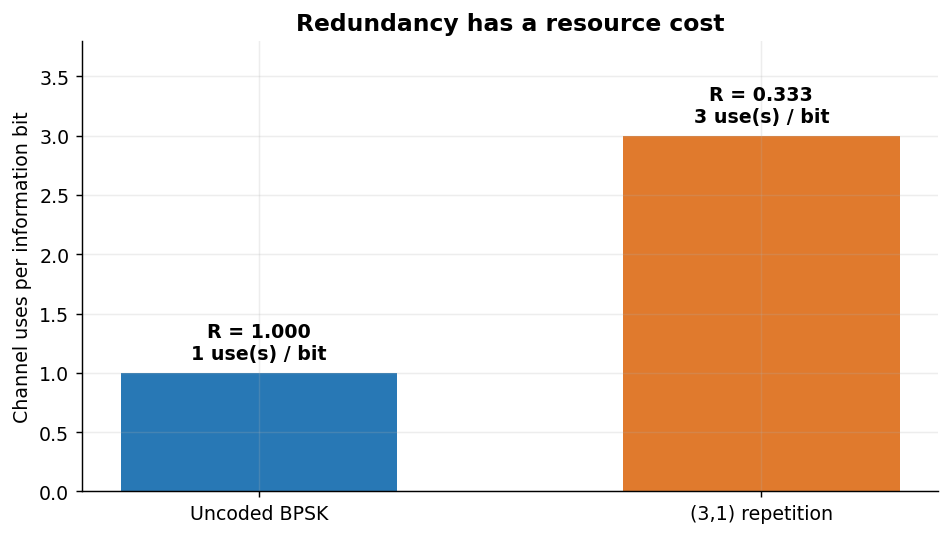

In [4]:

labels = ["Uncoded BPSK", "(3,1) repetition"]
rates = [1.0, R]
uses_per_info_bit = [1/r for r in rates]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(labels, uses_per_info_bit, color=[BLUE, ORANGE], width=0.55)
ax.set_ylabel("Channel uses per information bit")
ax.set_title("Redundancy has a resource cost")
ax.set_ylim(0, 3.8)
for bar, rate, uses in zip(bars, rates, uses_per_info_bit):
    ax.text(bar.get_x()+bar.get_width()/2, uses+0.08,
            f"R = {rate:.3f}\n{uses:.0f} use(s) / bit",
            ha="center", va="bottom", weight="bold")
plt.show()


## 3. Error detection: parity checks and syndromes

For a received vector \(r\), the syndrome is
\[
s=Hr^T\pmod 2.
\]
A zero syndrome means that the received vector is a valid codeword. A nonzero syndrome detects that the received vector is outside the code.

A crucial limitation appears for the all-bit error pattern \(e=111\): it transforms \(000\) into the other valid codeword \(111\), so the syndrome is zero. This is an **undetected error**, not a decoding success.

,Error pattern,Weight,Syndrome,Detected?,ML output,Decoded correctly?
0,000,0,00,False,000,True
1,001,1,01,True,000,True
2,010,1,11,True,000,True
3,011,2,10,True,111,False
4,100,1,10,True,000,True
5,101,2,11,True,111,False
6,110,2,01,True,111,False
7,111,3,00,False,111,False


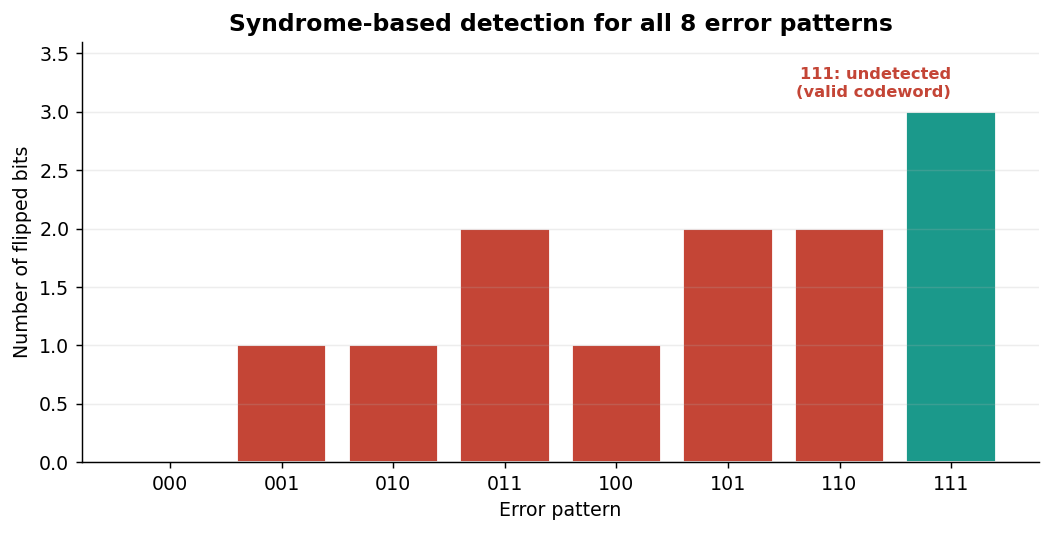

In [5]:
rows = []
for e in ALL_WORDS:
    s = syndrome(e)
    decoded, _ = nearest_codeword(e)  # assume 000 was transmitted
    rows.append({
        "Error pattern": "".join(map(str, e)),
        "Weight": int(e.sum()),
        "Syndrome": "".join(map(str, s)),
        "Detected?": bool(np.any(s)),
        "ML output": "".join(map(str, decoded)),
        "Decoded correctly?": bool(np.array_equal(decoded, CODEWORDS[0]))
    })
syndrome_table = pd.DataFrame(rows)
display(syndrome_table)

colors = [RED if row["Detected?"] else TEAL for row in rows]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(syndrome_table["Error pattern"], syndrome_table["Weight"],
       color=colors, edgecolor="white")
ax.set_ylim(0, 3.6)
ax.set_ylabel("Number of flipped bits")
ax.set_xlabel("Error pattern")
ax.set_title("Syndrome-based detection for all 8 error patterns")
ax.text(7, 3.13, "111: undetected\n(valid codeword)", ha="right",
        color=RED, fontsize=9, weight="bold")
ax.grid(axis="x", visible=False)
plt.show()

## 4. Maximum-likelihood (ML) versus maximum-a-posteriori (MAP) decoding

For equally likely codewords, MAP and ML are identical:
\[
\hat v_{\rm ML}=\arg\max_{v\in\mathcal C}P(r|v),
\qquad
\hat v_{\rm MAP}=\arg\max_{v\in\mathcal C}P(r|v)P(v).
\]

For a BSC with crossover probability \(p<1/2\), maximizing \(P(r|v)\) is equivalent to minimizing Hamming distance. MAP additionally uses prior probabilities \(P(v)\), so it can select a less-near codeword when that codeword was much more likely before reception.

Received word: 100
ML (equal prior): 000
MAP (equal prior): 000
MAP (P(000)=0.05, P(111)=0.95): 111
Log-posterior scores for [000, 111]: [-5.509  -4.7618]


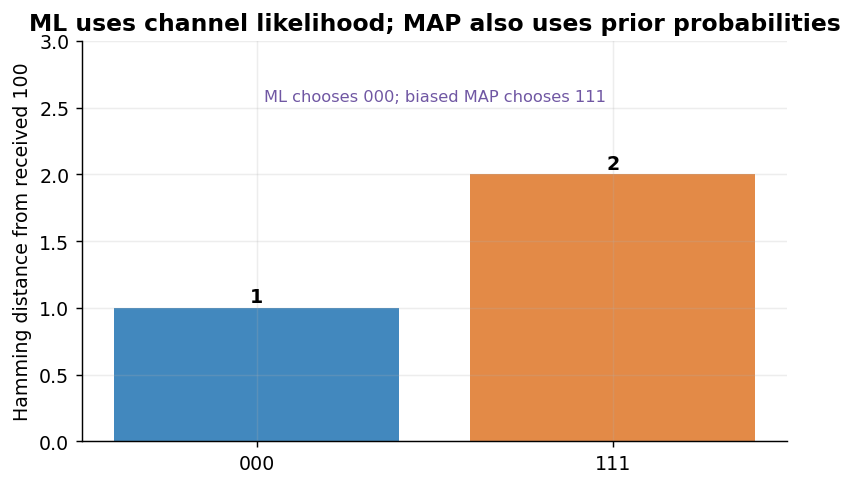

In [6]:
def decode_bsc_ml(received, p):
    if not 0 < p < 1:
        raise ValueError("Use 0 < p < 1.")
    log_likelihood = []
    for cw in CODEWORDS:
        d = hamming_distance(received, cw)
        log_likelihood.append(d*np.log(p) + (N-d)*np.log1p(-p))
    idx = int(np.argmax(log_likelihood))
    return CODEWORDS[idx].copy(), np.array(log_likelihood)

def decode_bsc_map(received, p, priors):
    priors = np.asarray(priors, dtype=float)
    if priors.shape != (2,) or np.any(priors <= 0):
        raise ValueError("priors must contain two positive probabilities.")
    priors = priors / priors.sum()
    log_posterior = []
    for i, cw in enumerate(CODEWORDS):
        d = hamming_distance(received, cw)
        ll = d*np.log(p) + (N-d)*np.log1p(-p)
        log_posterior.append(ll + np.log(priors[i]))
    idx = int(np.argmax(log_posterior))
    return CODEWORDS[idx].copy(), np.array(log_posterior)

example_r = np.array([1, 0, 0], dtype=np.int8)
ml_equal, _ = decode_bsc_ml(example_r, p=0.10)
map_equal, _ = decode_bsc_map(example_r, p=0.10, priors=[0.5, 0.5])
map_biased, logpost = decode_bsc_map(
    example_r, p=0.10, priors=[0.05, 0.95])

print("Received word:", "".join(map(str, example_r)))
print("ML (equal prior):", "".join(map(str, ml_equal)))
print("MAP (equal prior):", "".join(map(str, map_equal)))
print("MAP (P(000)=0.05, P(111)=0.95):", "".join(map(str, map_biased)))
print("Log-posterior scores for [000, 111]:", np.round(logpost, 4))

distances = [hamming_distance(example_r, cw) for cw in CODEWORDS]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([0, 1], distances, color=[BLUE, ORANGE], alpha=0.88)
ax.set_xticks([0, 1], ["000", "111"])
ax.set_ylabel("Hamming distance from received 100")
ax.set_title("ML uses channel likelihood; MAP also uses prior probabilities")
for i, value in enumerate(distances):
    ax.text(i, value+0.04, str(value), ha="center", weight="bold")
ax.text(0.5, 2.55, "ML chooses 000; biased MAP chooses 111",
        ha="center", fontsize=9, color=PURPLE)
ax.set_ylim(0, 3)
plt.show()

## 5. One complete transmission: corruption and correction

We send \(u=1\), encode it as \(111\), flip selected positions in the channel, and decode by ML. Change `flip_positions` to explore one error, two errors, or the undetectable three-bit substitution.

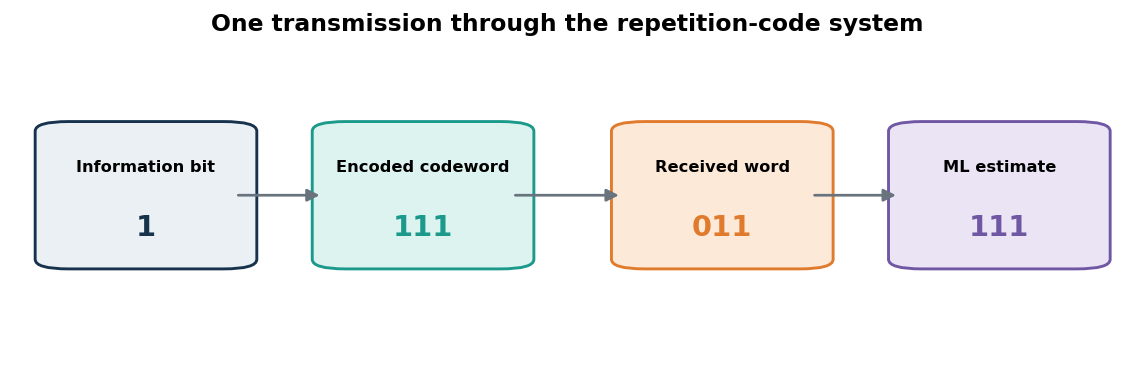

Transmitted u=1; codeword=111
Flipped positions (0-indexed)=[0]; received=011
Hamming distances to [000, 111] = [2, 1]
Decoded bit û=1; SUCCESS


In [7]:
def bsc_corrupt(word, flip_positions):
    out = np.asarray(word, dtype=np.int8).copy()
    for pos in flip_positions:
        if pos not in range(N):
            raise ValueError("Error positions must be 0, 1 or 2.")
        out[pos] ^= 1
    return out

u_tx = 1
v_tx = encode_bit(u_tx)
flip_positions = [0]  # Try [0, 2] and [0, 1, 2] as well.
r_rx = bsc_corrupt(v_tx, flip_positions)
v_hat, distances = nearest_codeword(r_rx)
u_hat = int(v_hat[0])

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axis("off")
stages = [
    (0.04, "Information bit", str(u_tx), LIGHT, NAVY),
    (0.29, "Encoded codeword", "".join(map(str, v_tx)), "#DDF3EF", TEAL),
    (0.56, "Received word", "".join(map(str, r_rx)), "#FCE9D8", ORANGE),
    (0.81, "ML estimate", "".join(map(str, v_hat)), "#EAE4F5", PURPLE),
]
for x, title, value, face, edge in stages:
    ax.add_patch(FancyBboxPatch(
        (x, 0.32), 0.16, 0.42,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        facecolor=face, edgecolor=edge, linewidth=1.6))
    ax.text(x+0.08, 0.62, title, ha="center", va="center",
            fontsize=9, weight="bold")
    ax.text(x+0.08, 0.43, value, ha="center", va="center",
            fontsize=16, weight="bold", color=edge)
for x1, x2 in [(0.20, 0.28), (0.45, 0.55), (0.72, 0.80)]:
    ax.add_patch(FancyArrowPatch((x1, 0.53), (x2, 0.53),
        arrowstyle="-|>", mutation_scale=14, color=GRAY, linewidth=1.5))
ax.set_title("One transmission through the repetition-code system", pad=8)
plt.show()

print(f"Transmitted u={u_tx}; codeword={''.join(map(str, v_tx))}")
print(f"Flipped positions (0-indexed)={flip_positions}; received={''.join(map(str, r_rx))}")
print(f"Hamming distances to [000, 111] = {distances.tolist()}")
print(f"Decoded bit û={u_hat}; {'SUCCESS' if u_hat == u_tx else 'DECODING ERROR'}")

## 6. Exact BSC error probabilities and Monte Carlo verification

Let \(p\) be the independent bit-flip probability of the BSC.

Before decoding, the bit error probability is \(p\). The repetition decoder makes a decision error if at least two of the three transmitted bits are flipped:
\[
P_{\rm e,decoded}
=\binom32p^2(1-p)+p^3
=3p^2-2p^3,\qquad 0\le p\le \tfrac12.
\]

For a transmitted codeword, the probability that the syndrome detects an error is \(3p(1-p)\). The undetected-error probability is \(p^3\), corresponding to all three bits flipping.

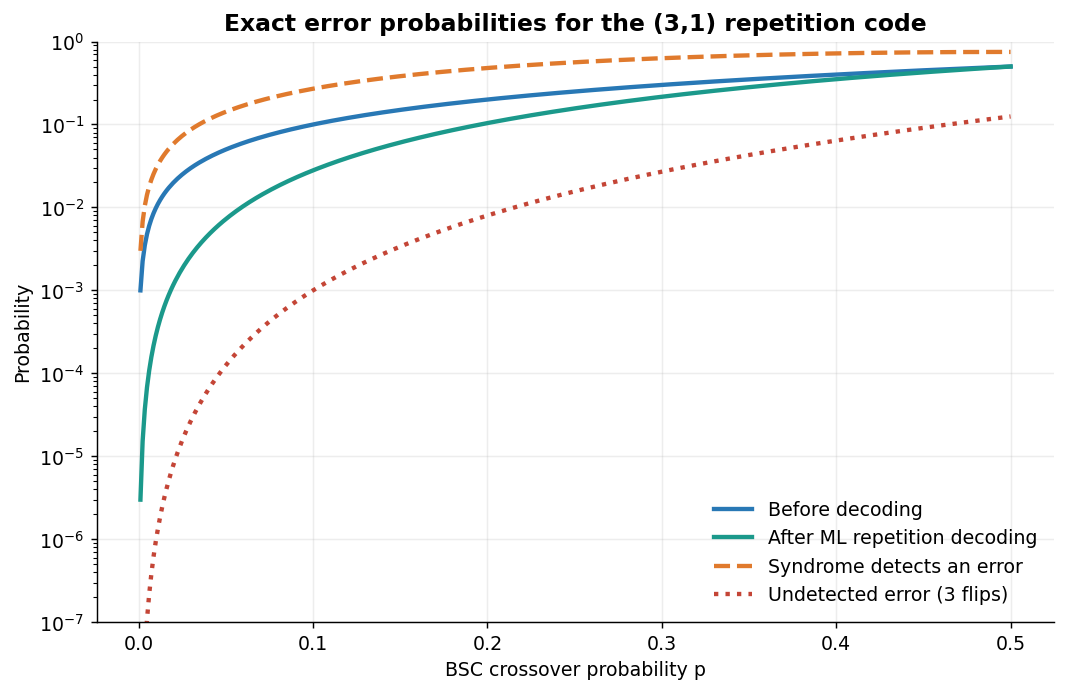

,p,raw BER (MC),raw BER (theory),decoded BER (MC),decoded BER (theory),detected errors (MC),detected errors (theory)
0,0.020000,0.019544,0.020000,0.001096,0.001184,0.057536,0.058800
1,0.050000,0.049904,0.050000,0.007148,0.007250,0.142340,0.142500
2,0.100000,0.099891,0.100000,0.027740,0.028000,0.269836,0.270000
3,0.200000,0.199615,0.200000,0.104228,0.104000,0.479336,0.480000
4,0.300000,0.300156,0.300000,0.216528,0.216000,0.629692,0.630000
5,0.400000,0.400241,0.400000,0.351380,0.352000,0.719776,0.720000


In [8]:
def bsc_theory(p):
    p = np.asarray(p, dtype=float)
    return p, 3*p**2 - 2*p**3, 3*p*(1-p), p**3

def simulate_bsc(p, n_frames=250_000, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    bits = rng.integers(0, 2, size=n_frames, dtype=np.int8)
    tx = np.repeat(bits[:, None], 3, axis=1)
    errors = (rng.random((n_frames, 3)) < p).astype(np.int8)
    rx = tx ^ errors
    decoded = (rx.sum(axis=1) >= 2).astype(np.int8)
    syndromes = (rx @ H.T) % 2
    detected = np.any(syndromes != 0, axis=1)
    return {
        "raw channel BER": float(errors.mean()),
        "decoded BER/WER": float(np.mean(decoded != bits)),
        "syndrome detection probability": float(detected.mean())
    }

p_grid = np.linspace(0.001, 0.5, 400)
p_before, p_after, p_detected, p_undetected = bsc_theory(p_grid)

fig, ax = plt.subplots(figsize=(9.5, 5.8))
ax.semilogy(p_grid, p_before, label="Before decoding", color=BLUE)
ax.semilogy(p_grid, p_after, label="After ML repetition decoding", color=TEAL)
ax.semilogy(p_grid, p_detected, label="Syndrome detects an error",
            color=ORANGE, linestyle="--")
ax.semilogy(p_grid, p_undetected, label="Undetected error (3 flips)",
            color=RED, linestyle=":")
ax.set_xlabel("BSC crossover probability p")
ax.set_ylabel("Probability")
ax.set_ylim(1e-7, 1)
ax.set_title("Exact error probabilities for the (3,1) repetition code")
ax.legend()
plt.show()

p_test = [0.02, 0.05, 0.10, 0.20, 0.30, 0.40]
mc_rng = np.random.default_rng(SEED + 1)
mc_rows = []
for p0 in p_test:
    result = simulate_bsc(p0, rng=mc_rng)
    mc_rows.append({
        "p": p0,
        "raw BER (MC)": result["raw channel BER"],
        "raw BER (theory)": p0,
        "decoded BER (MC)": result["decoded BER/WER"],
        "decoded BER (theory)": 3*p0**2 - 2*p0**3,
        "detected errors (MC)": result["syndrome detection probability"],
        "detected errors (theory)": 3*p0*(1-p0)
    })
display(pd.DataFrame(mc_rows).style.format("{:.6f}"))


### 6.1 BER versus WER

The **bit error rate (BER)** is the probability that a decoded information bit is wrong. The **word error rate (WER)** is the probability that an entire decoded message block is wrong. In this \((3,1)\) example, each message contains only one bit, so BER and WER are numerically identical after decoding. For a code with \(k>1\), they generally differ.


## 7. Binary erasure channel (BEC)

A BEC either delivers a bit correctly or marks it as an erasure. Unlike a flip, an erasure tells the decoder **which position is unknown**.

For the threefold repetition code, one surviving copy is enough to recover the bit. Therefore:
- uncoded erasure probability: \(\epsilon\);
- residual block erasure after repetition decoding: \(\epsilon^3\), because all three copies must be erased.

This assumes erasure locations are known and surviving symbols are not flipped.

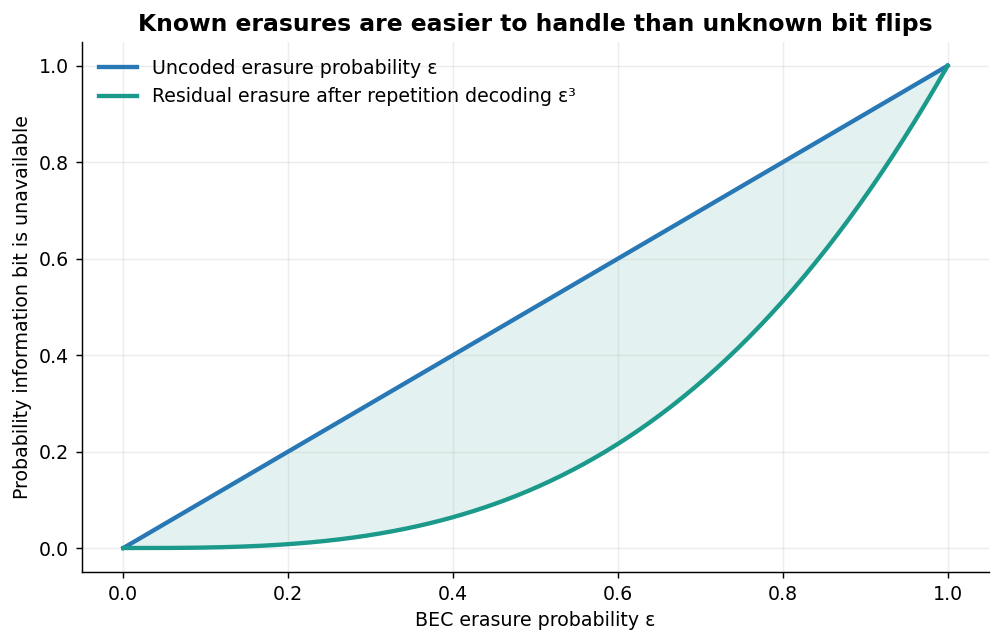

,epsilon,residual erasure (MC),residual erasure (theory)
0,0.050000,0.000125,0.000125
1,0.150000,0.003305,0.003375
2,0.300000,0.027075,0.027000
3,0.500000,0.124280,0.125000
4,0.700000,0.341845,0.343000


In [9]:
eps = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(9, 5.3))
ax.plot(eps, eps, label="Uncoded erasure probability ε", color=BLUE)
ax.plot(eps, eps**3, label="Residual erasure after repetition decoding ε³",
        color=TEAL)
ax.fill_between(eps, eps**3, eps, alpha=0.12, color=TEAL)
ax.set_xlabel("BEC erasure probability ε")
ax.set_ylabel("Probability information bit is unavailable")
ax.set_title("Known erasures are easier to handle than unknown bit flips")
ax.legend()
plt.show()

def simulate_bec(epsilon, n_frames=200_000, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    erased = rng.random((n_frames, 3)) < epsilon
    return float(np.all(erased, axis=1).mean())

bec_rng = np.random.default_rng(SEED + 2)
bec_rows = []
for e in [0.05, 0.15, 0.30, 0.50, 0.70]:
    bec_rows.append({
        "epsilon": e,
        "residual erasure (MC)": simulate_bec(e, rng=bec_rng),
        "residual erasure (theory)": e**3
    })
display(pd.DataFrame(bec_rows).style.format("{:.6f}"))

## 8. BPSK modulation and AWGN observations

For BPSK, bits are mapped to antipodal signal points. We use
\[
0\mapsto +\sqrt{E_s},\qquad 1\mapsto-\sqrt{E_s},
\]
and the received sample is \(y=x+n\), where \(n\sim\mathcal N(0,N_0/2)\).

A hard detector keeps only the sign of each sample. A soft detector retains reliability information in the sample magnitude. Soft ML decoding for this repetition code chooses the codeword with the closest Euclidean signal vector; equivalently, it uses the sign of the sum of the three real observations.

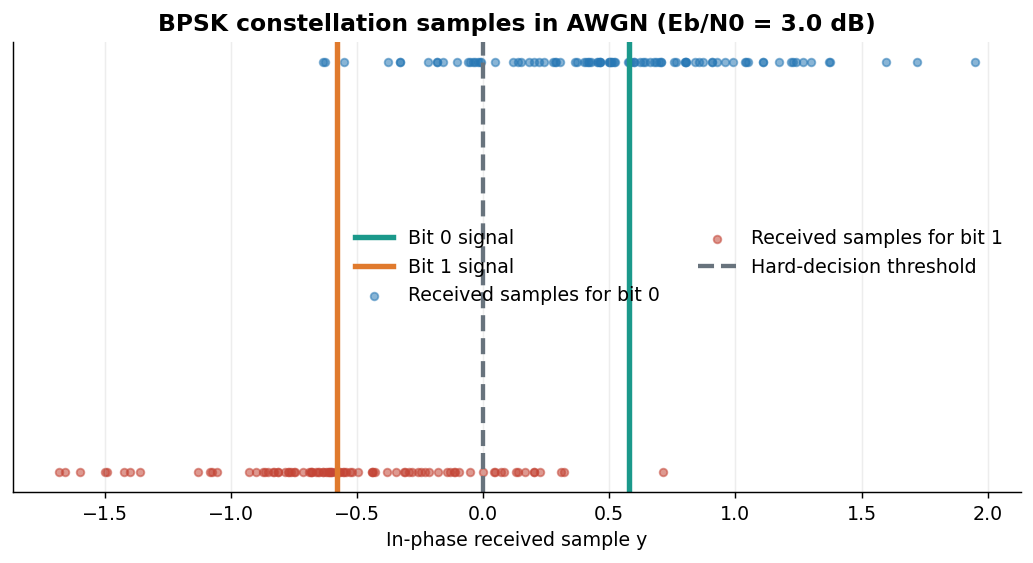

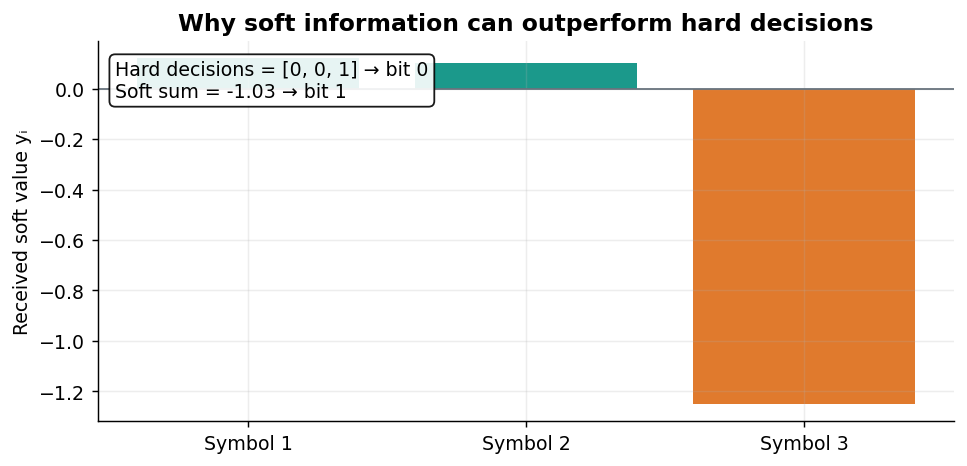

In [10]:
# Constellation / received-sample illustration
ebn0_demo_db = 3.0
gamma_demo = 10**(ebn0_demo_db/10)
Es_demo = R  # normalize Eb=1, so Es=R*Eb
N0_demo = 1/gamma_demo
sigma_demo = np.sqrt(N0_demo/2)
A_demo = np.sqrt(Es_demo)

rng_demo = np.random.default_rng(SEED + 3)
bits_demo = rng_demo.integers(0, 2, size=180)
symbols_demo = (1 - 2*bits_demo) * A_demo
received_demo = symbols_demo + rng_demo.normal(0, sigma_demo, size=len(symbols_demo))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvline(+A_demo, color=TEAL, linewidth=3, label="Bit 0 signal")
ax.axvline(-A_demo, color=ORANGE, linewidth=3, label="Bit 1 signal")
ax.scatter(received_demo[bits_demo == 0],
           np.zeros(np.sum(bits_demo == 0)) + 0.03,
           s=18, alpha=0.55, color=BLUE, label="Received samples for bit 0")
ax.scatter(received_demo[bits_demo == 1],
           np.zeros(np.sum(bits_demo == 1)) - 0.03,
           s=18, alpha=0.55, color=RED, label="Received samples for bit 1")
ax.axvline(0, color=GRAY, linestyle="--", label="Hard-decision threshold")
ax.set_yticks([])
ax.set_xlabel("In-phase received sample y")
ax.set_title(f"BPSK constellation samples in AWGN (Eb/N0 = {ebn0_demo_db:.1f} dB)")
ax.legend(ncol=2)
plt.show()

# Deliberate example where soft ML and hard majority differ.
y_soft_example = np.array([0.12, 0.10, -1.25])
hard_bits = (y_soft_example < 0).astype(int)
hard_decoded = int(hard_bits.sum() >= 2)
soft_decoded = int(y_soft_example.sum() < 0)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.bar(np.arange(3), y_soft_example,
       color=[TEAL if x >= 0 else ORANGE for x in y_soft_example])
ax.axhline(0, color=GRAY, linewidth=1)
ax.set_xticks([0, 1, 2], ["Symbol 1", "Symbol 2", "Symbol 3"])
ax.set_ylabel("Received soft value yᵢ")
ax.set_title("Why soft information can outperform hard decisions")
ax.text(0.02, 0.95,
        f"Hard decisions = {hard_bits.tolist()} → bit {hard_decoded}\n"
        f"Soft sum = {y_soft_example.sum():.2f} → bit {soft_decoded}",
        transform=ax.transAxes, va="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))
plt.show()


### 8.1 BPSK as a time-domain waveform

BPSK changes the carrier phase by \(\pi\) between the two binary symbols. The plot uses a simple carrier with a phase reversal at each bit boundary, then adds Gaussian noise to show what the receiver observes.


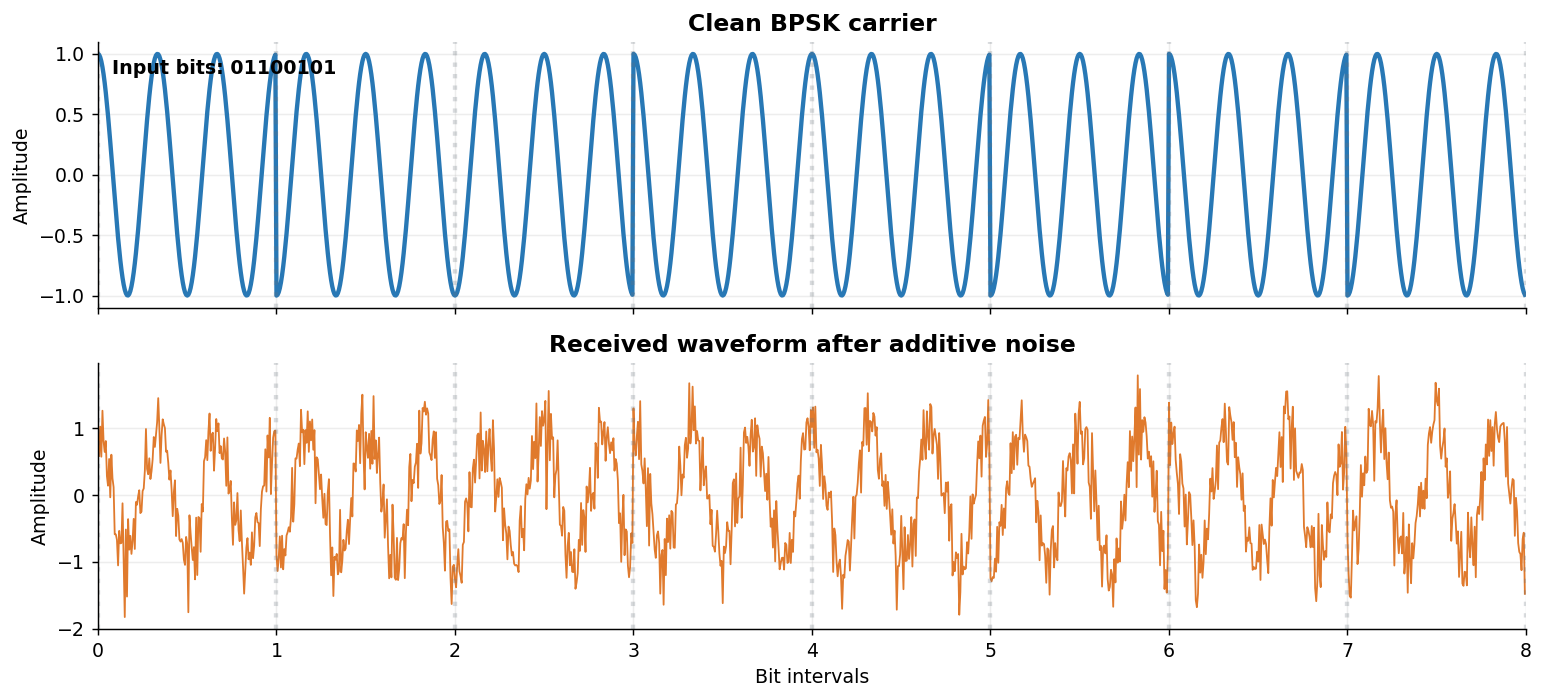

In [11]:

bits_wave = np.array([0, 1, 1, 0, 0, 1, 0, 1], dtype=np.int8)
samples_per_bit = 160
fc_cycles_per_bit = 3
local_t = np.arange(samples_per_bit) / samples_per_bit
t_wave = np.arange(len(bits_wave)*samples_per_bit) / samples_per_bit
clean_wave = np.concatenate([
    (1 - 2*b) * np.cos(2*np.pi*fc_cycles_per_bit*local_t)
    for b in bits_wave
])
wave_rng = np.random.default_rng(SEED + 30)
noisy_wave = clean_wave + wave_rng.normal(0, 0.32, size=clean_wave.size)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(t_wave, clean_wave, color=BLUE)
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Clean BPSK carrier")
axes[1].plot(t_wave, noisy_wave, color=ORANGE, linewidth=1.0)
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Bit intervals")
axes[1].set_title("Received waveform after additive noise")
for ax in axes:
    for boundary in range(len(bits_wave)+1):
        ax.axvline(boundary, color=GRAY, alpha=0.25, linestyle=":")
    ax.set_xlim(0, len(bits_wave))
axes[0].text(0.01, 0.88, "Input bits: " + "".join(map(str, bits_wave)),
             transform=axes[0].transAxes, weight="bold")
plt.tight_layout()
plt.show()


## 9. BER over AWGN: uncoded, hard-decision and soft-ML repetition decoding

For coherent BPSK:
\[
P_{b,\rm uncoded}=Q\!\left(\sqrt{2E_b/N_0}\right).
\]

Since \(E_s=R E_b\), the error probability of each hard-demodulated coded symbol is
\[
p_s=Q\!\left(\sqrt{2R E_b/N_0}\right).
\]
The hard-decision repetition decoder then has \(P_{b,\rm hard}=3p_s^2-2p_s^3\).

For soft ML, the three real observations are combined before making a decision. For this particular repetition code,
\[
P_{b,\rm softML}=Q\!\left(\sqrt{2E_b/N_0}\right).
\]
Thus soft ML has **0 dB gain** over uncoded BPSK when both are compared at the same information-bit energy. This is a useful sanity check, not a plotting error.

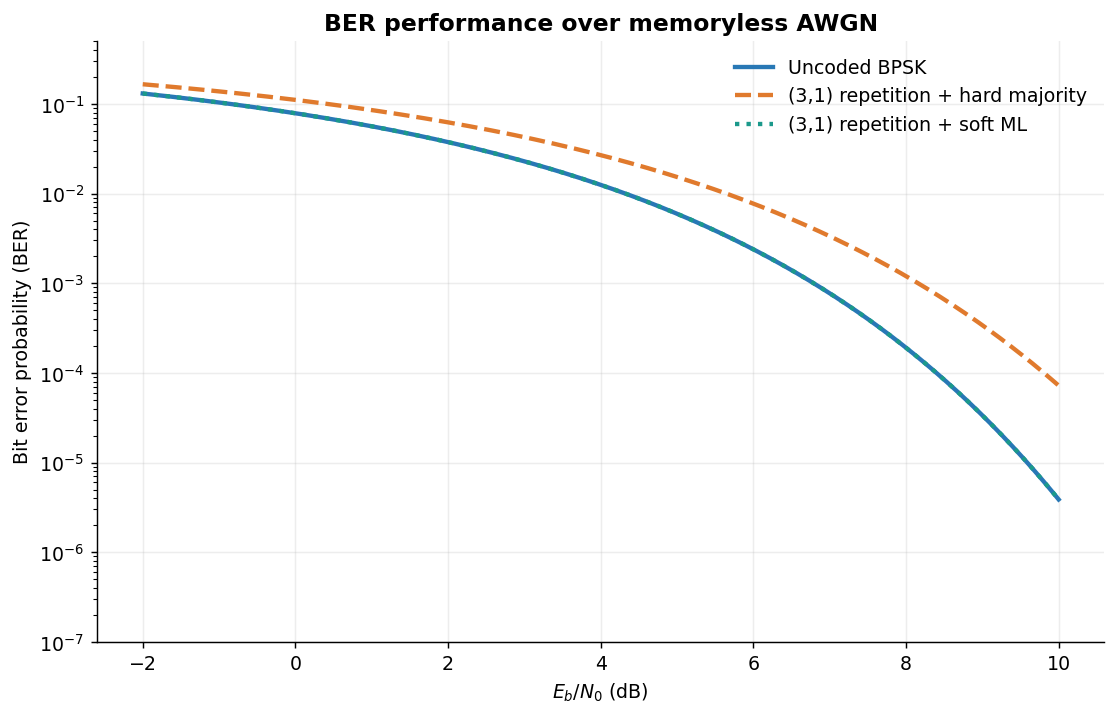

,Eb/N0 (dB),Frames,Uncoded BPSK BER (MC),Repetition hard BER (MC),Repetition soft ML BER (MC)
0,-1.0,200000,1.027e-01,1.384e-01,1.033e-01
1,0.0,200000,7.880e-02,1.111e-01,7.816e-02
2,1.0,200000,5.629e-02,8.521e-02,5.633e-02
3,2.0,200000,3.716e-02,6.172e-02,3.748e-02
4,3.0,200000,2.228e-02,4.351e-02,2.322e-02
5,4.0,200000,1.230e-02,2.661e-02,1.263e-02
6,5.0,200000,5.990e-03,1.500e-02,5.995e-03
7,6.0,200000,2.310e-03,7.950e-03,2.250e-03


In [12]:
def Q(x):
    return 0.5 * erfc(np.asarray(x) / np.sqrt(2))

def ber_uncoded_bpsk(ebn0_linear):
    return Q(np.sqrt(2*np.asarray(ebn0_linear)))

def ber_repetition_hard(ebn0_linear, rate=R):
    p_symbol = Q(np.sqrt(2*rate*np.asarray(ebn0_linear)))
    return 3*p_symbol**2 - 2*p_symbol**3

def ber_repetition_soft(ebn0_linear):
    return ber_uncoded_bpsk(ebn0_linear)

def simulate_awgn_point(ebn0_db, n_frames=200_000, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    gamma_b = 10**(ebn0_db/10)
    N0 = 1/gamma_b  # Eb normalized to 1
    sigma = np.sqrt(N0/2)
    amplitude_uncoded = 1.0
    amplitude_coded = np.sqrt(R)

    bits = rng.integers(0, 2, size=n_frames, dtype=np.int8)
    bipolar = 1 - 2*bits

    y_uncoded = bipolar*amplitude_uncoded + rng.normal(0, sigma, n_frames)
    dec_uncoded = (y_uncoded < 0).astype(np.int8)

    tx_coded = bipolar[:, None]*amplitude_coded
    y_coded = tx_coded + rng.normal(0, sigma, size=(n_frames, 3))
    dec_soft = (y_coded.sum(axis=1) < 0).astype(np.int8)
    hard_symbols = (y_coded < 0).astype(np.int8)
    dec_hard = (hard_symbols.sum(axis=1) >= 2).astype(np.int8)

    return {
        "Uncoded BPSK": int(np.sum(dec_uncoded != bits)),
        "Repetition hard": int(np.sum(dec_hard != bits)),
        "Repetition soft ML": int(np.sum(dec_soft != bits)),
        "Frames": n_frames
    }

ebn0_db = np.linspace(-2, 10, 500)
ebn0_lin = 10**(ebn0_db/10)
ber_u = ber_uncoded_bpsk(ebn0_lin)
ber_h = ber_repetition_hard(ebn0_lin)
ber_s = ber_repetition_soft(ebn0_lin)

fig, ax = plt.subplots(figsize=(10, 6))
ax.semilogy(ebn0_db, ber_u, color=BLUE, label="Uncoded BPSK")
ax.semilogy(ebn0_db, ber_h, color=ORANGE, linestyle="--",
            label="(3,1) repetition + hard majority")
ax.semilogy(ebn0_db, ber_s, color=TEAL, linestyle=":",
            label="(3,1) repetition + soft ML")
ax.set_xlabel(r"$E_b/N_0$ (dB)")
ax.set_ylabel("Bit error probability (BER)")
ax.set_ylim(1e-7, 0.5)
ax.set_title("BER performance over memoryless AWGN")
ax.legend()
plt.show()

# Monte Carlo markers: use a range with enough errors to estimate BER.
awgn_rng = np.random.default_rng(SEED + 4)
awgn_mc_rows = []
for db in [-1, 0, 1, 2, 3, 4, 5, 6]:
    counts = simulate_awgn_point(db, n_frames=200_000, rng=awgn_rng)
    row = {"Eb/N0 (dB)": db, "Frames": counts["Frames"]}
    for key in ["Uncoded BPSK", "Repetition hard", "Repetition soft ML"]:
        row[key + " BER (MC)"] = counts[key] / counts["Frames"]
    awgn_mc_rows.append(row)

awgn_mc = pd.DataFrame(awgn_mc_rows)
display(awgn_mc.style.format({
    "Eb/N0 (dB)": "{:.1f}",
    "Uncoded BPSK BER (MC)": "{:.3e}",
    "Repetition hard BER (MC)": "{:.3e}",
    "Repetition soft ML BER (MC)": "{:.3e}"
}))

## 10. BPSK-constrained Shannon limit

The Shannon limit is a **capacity threshold**, not the measured BER curve of this short code. We calculate the capacity of a binary-input, continuous-output AWGN channel (BPSK input alphabet) and solve for the \(E_b/N_0\) at which capacity equals the code rate.

For equiprobable BPSK with \(E_s/N_0=\gamma_s\):
\[
C_{\rm BPSK}
=1-\mathbb E_{Y|X=+1}\left[
\log_2(1+e^{-L(Y)})
\right],
\qquad L(y)=4\sqrt{\gamma_s}\,y.
\]
The expectation is evaluated numerically with Gauss–Hermite quadrature.

**Validation:** at \(R=1/2\), the result should be approximately \(0.188\) dB, matching the table in Chapter 1. We also calculate the threshold for this notebook's rate \(R=1/3\).

BPSK-constrained Shannon limit at R=1/3: -0.4954 dB
Validation at R=1/2: 0.1871 dB (book value ≈ 0.188 dB)


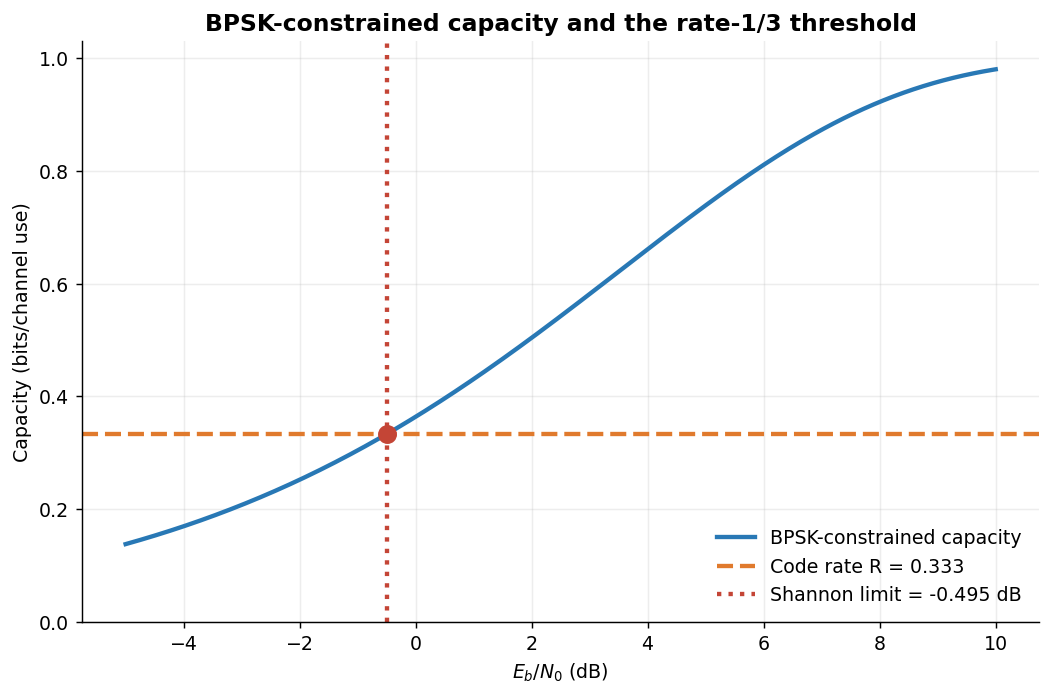

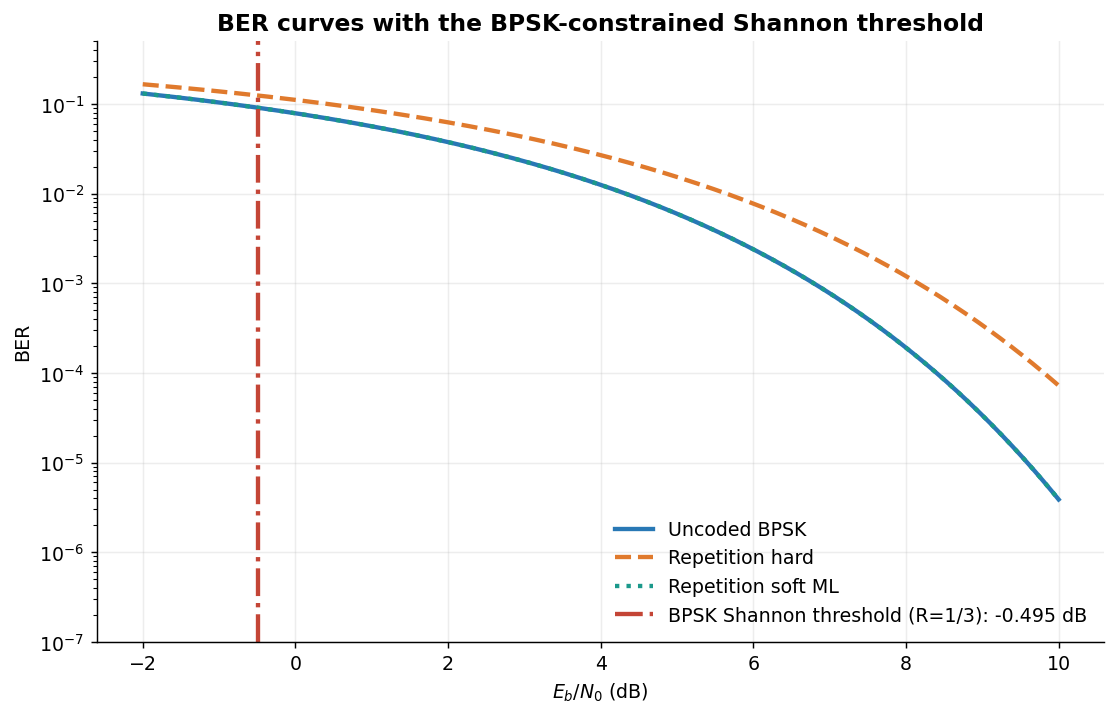

The vertical line is a capacity threshold, not a promise that this
particular length-3 repetition code achieves reliable decoding there.


In [13]:
GH_NODES, GH_WEIGHTS = np.polynomial.hermite.hermgauss(120)

def bpsk_capacity_from_esn0(esn0_linear):
    """
    Binary-input BPSK capacity in bits/channel use.
    Y = +/-sqrt(Es/N0) + Z, where Z ~ N(0, 1/2).
    """
    a = np.sqrt(np.asarray(esn0_linear, dtype=float))
    y_given_plus = np.expand_dims(a, axis=-1) + GH_NODES
    llr = 4*np.expand_dims(a, axis=-1)*y_given_plus
    loss = np.logaddexp(0, -llr) / np.log(2)
    expectation = np.sum(GH_WEIGHTS*loss, axis=-1) / np.sqrt(np.pi)
    return 1 - expectation

def bpsk_capacity_from_ebn0(ebn0_db, rate):
    ebn0_linear = 10**(np.asarray(ebn0_db)/10)
    return bpsk_capacity_from_esn0(rate*ebn0_linear)

def bpsk_shannon_limit_db(rate):
    objective = lambda db: float(bpsk_capacity_from_ebn0(db, rate) - rate)
    return brentq(objective, -20, 15)

limit_R13 = bpsk_shannon_limit_db(1/3)
limit_R12 = bpsk_shannon_limit_db(1/2)

print(f"BPSK-constrained Shannon limit at R=1/3: {limit_R13:.4f} dB")
print(f"Validation at R=1/2: {limit_R12:.4f} dB (book value ≈ 0.188 dB)")
assert abs(limit_R12 - 0.188) < 0.01, "Capacity normalization check failed."

db_grid = np.linspace(-5, 10, 350)
capacity_r13 = bpsk_capacity_from_ebn0(db_grid, R)

fig, ax = plt.subplots(figsize=(9.5, 5.8))
ax.plot(db_grid, capacity_r13, color=BLUE, label="BPSK-constrained capacity")
ax.axhline(R, color=ORANGE, linestyle="--", label=f"Code rate R = {R:.3f}")
ax.axvline(limit_R13, color=RED, linestyle=":",
           label=f"Shannon limit = {limit_R13:.3f} dB")
ax.scatter([limit_R13], [R], s=90, color=RED, zorder=5)
ax.set_xlabel(r"$E_b/N_0$ (dB)")
ax.set_ylabel("Capacity (bits/channel use)")
ax.set_ylim(0, 1.03)
ax.set_title("BPSK-constrained capacity and the rate-1/3 threshold")
ax.legend()
plt.show()

# Overlay the capacity threshold on BER performance curves.
fig, ax = plt.subplots(figsize=(10, 6))
ax.semilogy(ebn0_db, ber_u, color=BLUE, label="Uncoded BPSK")
ax.semilogy(ebn0_db, ber_h, color=ORANGE, linestyle="--", label="Repetition hard")
ax.semilogy(ebn0_db, ber_s, color=TEAL, linestyle=":", label="Repetition soft ML")
ax.axvline(limit_R13, color=RED, linestyle="-.",
           label=f"BPSK Shannon threshold (R=1/3): {limit_R13:.3f} dB")
ax.set_xlabel(r"$E_b/N_0$ (dB)")
ax.set_ylabel("BER")
ax.set_ylim(1e-7, 0.5)
ax.set_title("BER curves with the BPSK-constrained Shannon threshold")
ax.legend()
plt.show()

print("The vertical line is a capacity threshold, not a promise that this")
print("particular length-3 repetition code achieves reliable decoding there.")

## 11. Coding gain: hard versus soft decisions

The textbook's high-SNR asymptotic estimates for a binary block code are
\[
\gamma_{\rm soft}\approx10\log_{10}(R\,d_{\min}),
\qquad
\gamma_{\rm hard}\approx10\log_{10}\left(\frac12R\,d_{\min}\right).
\]

For the \((3,1)\) repetition code:
- soft-decision asymptotic gain: \(10\log_{10}(1)=0\) dB;
- hard-decision asymptotic gain: \(10\log_{10}(1/2)\approx-3.01\) dB.

We also compute **finite-BER coding gain** numerically. Positive gain means the coded system needs less \(E_b/N_0\) than uncoded BPSK to hit the same BER; negative gain means it needs more.

For a very short code such as this repetition code, keep the distance-based asymptotic estimate separate from the exact finite-BER curve. The table below is computed from the exact BSC hard-decision expression combined with the AWGN symbol-error probability; it is the appropriate finite-operating-point comparison for this specific code.


,Target BER,Uncoded Eb/N0 (dB),Soft ML Eb/N0 (dB),Hard ML Eb/N0 (dB),Soft gain (dB),Hard gain (dB)
0,1e-02,4.323,4.323,5.646,0.000,-1.323
1,1e-03,6.790,6.790,8.158,0.000,-1.369
2,1e-04,8.398,8.398,9.806,0.000,-1.408
3,1e-05,9.588,9.588,11.029,0.000,-1.441


Asymptotic soft-decision gain: 0.000 dB
Asymptotic hard-decision gain: -3.010 dB


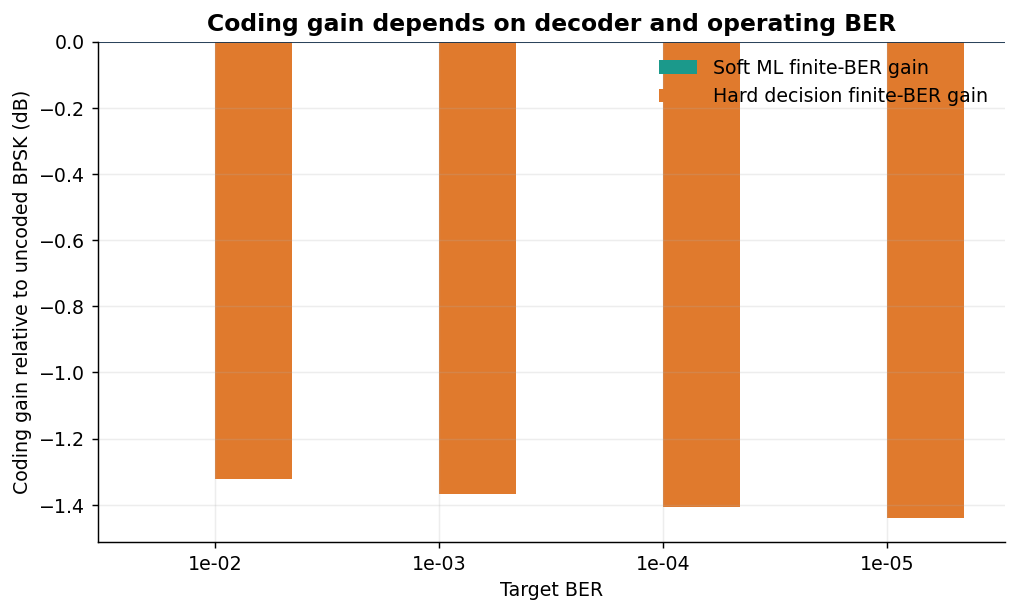

In [14]:
def required_ebn0_db(target_ber, mode="uncoded"):
    def objective(db):
        gamma = 10**(db/10)
        if mode in ("uncoded", "soft"):
            value = float(ber_uncoded_bpsk(gamma))
        elif mode == "hard":
            value = float(ber_repetition_hard(gamma))
        else:
            raise ValueError("mode must be 'uncoded', 'soft' or 'hard'")
        return value - target_ber
    return brentq(objective, -15, 35)

gain_soft_asym = 10*np.log10(R*D_MIN)
gain_hard_asym = 10*np.log10(0.5*R*D_MIN)

targets = [1e-2, 1e-3, 1e-4, 1e-5]
gain_rows = []
for target in targets:
    req_u = required_ebn0_db(target, "uncoded")
    req_s = required_ebn0_db(target, "soft")
    req_h = required_ebn0_db(target, "hard")
    gain_rows.append({
        "Target BER": target,
        "Uncoded Eb/N0 (dB)": req_u,
        "Soft ML Eb/N0 (dB)": req_s,
        "Hard ML Eb/N0 (dB)": req_h,
        "Soft gain (dB)": req_u-req_s,
        "Hard gain (dB)": req_u-req_h
    })

gain_table = pd.DataFrame(gain_rows)
display(gain_table.style.format({
    "Target BER": "{:.0e}",
    "Uncoded Eb/N0 (dB)": "{:.3f}",
    "Soft ML Eb/N0 (dB)": "{:.3f}",
    "Hard ML Eb/N0 (dB)": "{:.3f}",
    "Soft gain (dB)": "{:.3f}",
    "Hard gain (dB)": "{:.3f}"
}))
print(f"Asymptotic soft-decision gain: {gain_soft_asym:.3f} dB")
print(f"Asymptotic hard-decision gain: {gain_hard_asym:.3f} dB")

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(targets)); width = 0.34
ax.bar(x-width/2, gain_table["Soft gain (dB)"], width,
       color=TEAL, label="Soft ML finite-BER gain")
ax.bar(x+width/2, gain_table["Hard gain (dB)"], width,
       color=ORANGE, label="Hard decision finite-BER gain")
ax.axhline(0, color=NAVY, linewidth=1)
ax.set_xticks(x, [f"{t:.0e}" for t in targets])
ax.set_xlabel("Target BER")
ax.set_ylabel("Coding gain relative to uncoded BPSK (dB)")
ax.set_title("Coding gain depends on decoder and operating BER")
ax.legend()
plt.show()

## 12. Random errors, burst errors and interleaving

A BSC models independent errors. Real channels can also have memory: errors may arrive in clusters (bursts). A repetition code corrects one error per 3-bit block, but a burst of three adjacent channel errors can corrupt all bits of one codeword.

Interleaving rearranges symbols from several codewords before transmission. A short burst is then spread across multiple codewords, potentially converting an uncorrectable burst into several individually correctable single-bit errors. Interleaving does **not** change the code rate; it changes the error pattern seen by each decoder.

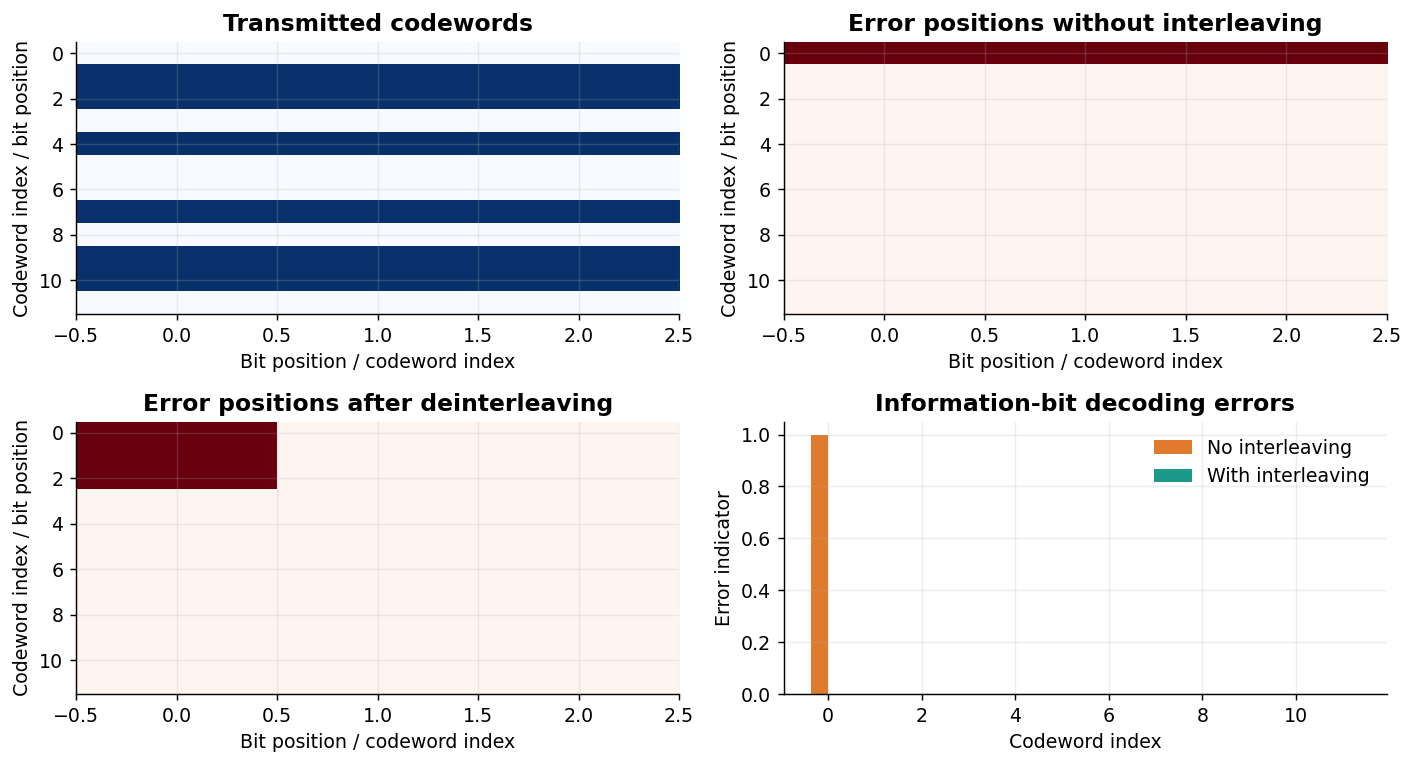

Decoding errors without interleaving: 1
Decoding errors with interleaving   : 0


In [15]:
# Deterministic burst example
n_words = 12
message_bits = np.array([0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0], dtype=np.int8)
cw_matrix = np.repeat(message_bits[:, None], 3, axis=1)

burst = np.zeros(cw_matrix.size, dtype=np.int8)
burst[:3] = 1  # three adjacent channel errors

# No interleaving: codeword-major serialization
rx_no_int = (cw_matrix.ravel() ^ burst).reshape(n_words, 3)

# Interleaving: transmit column-major, then deinterleave at receiver
tx_interleaved = cw_matrix.T.ravel()
rx_interleaved_stream = tx_interleaved ^ burst
rx_int = rx_interleaved_stream.reshape(3, n_words).T

dec_no_int = (rx_no_int.sum(axis=1) >= 2).astype(np.int8)
dec_int = (rx_int.sum(axis=1) >= 2).astype(np.int8)

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0, 0].imshow(cw_matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0, 0].set_title("Transmitted codewords")
axes[0, 1].imshow(rx_no_int != cw_matrix, cmap="Reds", vmin=0, vmax=1, aspect="auto")
axes[0, 1].set_title("Error positions without interleaving")
axes[1, 0].imshow(rx_int != cw_matrix, cmap="Reds", vmin=0, vmax=1, aspect="auto")
axes[1, 0].set_title("Error positions after deinterleaving")
axes[1, 1].bar(np.arange(n_words)-0.18, dec_no_int != message_bits,
               width=0.36, color=ORANGE, label="No interleaving")
axes[1, 1].bar(np.arange(n_words)+0.18, dec_int != message_bits,
               width=0.36, color=TEAL, label="With interleaving")
axes[1, 1].set_title("Information-bit decoding errors")
axes[1, 1].set_xlabel("Codeword index")
axes[1, 1].set_ylabel("Error indicator")
axes[1, 1].legend()
for ax in axes.flat[:3]:
    ax.set_xlabel("Bit position / codeword index")
    ax.set_ylabel("Codeword index / bit position")
plt.tight_layout()
plt.show()

print("Decoding errors without interleaving:", int(np.sum(dec_no_int != message_bits)))
print("Decoding errors with interleaving   :", int(np.sum(dec_int != message_bits)))

### 12.1 A Gilbert–Elliott (two-state) channel

We now simulate a channel with a good state \(G\) and a bad state \(B\). The channel switches between states with nonzero transition probabilities, and the bit-flip probability depends on the current state.

The same generated error sequence is applied to the non-interleaved and interleaved transmissions. This is a controlled comparison of how the ordering of symbols changes the damage seen by each 3-bit codeword.

,System,Channel raw BER,Decoded BER/WER
0,No interleaving,0.00723,0.00345
1,With interleaving,0.00723,0.00020


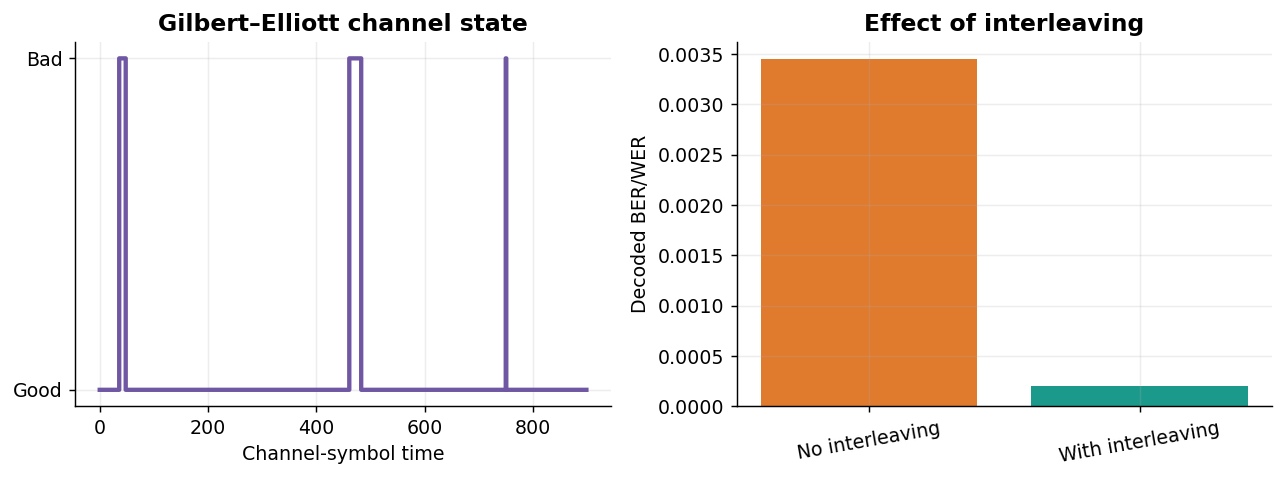

In [16]:
def gilbert_elliott_error_sequence(length, p_good=0.001, p_bad=0.25,
                                   p_g_to_b=0.003, p_b_to_g=0.12,
                                   rng=None):
    if rng is None:
        rng = np.random.default_rng()
    states = np.zeros(length, dtype=np.int8)  # 0=good, 1=bad
    for i in range(1, length):
        if states[i-1] == 0:
            states[i] = int(rng.random() < p_g_to_b)
        else:
            states[i] = int(not (rng.random() < p_b_to_g))
    flip_prob = np.where(states == 0, p_good, p_bad)
    errors = (rng.random(length) < flip_prob).astype(np.int8)
    return errors, states

K_GE = 20_000
ge_rng = np.random.default_rng(SEED + 5)
ge_errors, ge_states = gilbert_elliott_error_sequence(3*K_GE, rng=ge_rng)
ge_bits = ge_rng.integers(0, 2, size=K_GE, dtype=np.int8)
ge_cw = np.repeat(ge_bits[:, None], 3, axis=1)

# Non-interleaved
ge_rx_no = (ge_cw.ravel() ^ ge_errors).reshape(K_GE, 3)
ge_dec_no = (ge_rx_no.sum(axis=1) >= 2).astype(np.int8)

# Interleaved
ge_rx_int_stream = ge_cw.T.ravel() ^ ge_errors
ge_rx_int = ge_rx_int_stream.reshape(3, K_GE).T
ge_dec_int = (ge_rx_int.sum(axis=1) >= 2).astype(np.int8)

ge_results = pd.DataFrame([
    {"System": "No interleaving",
     "Channel raw BER": ge_errors.mean(),
     "Decoded BER/WER": np.mean(ge_dec_no != ge_bits)},
    {"System": "With interleaving",
     "Channel raw BER": ge_errors.mean(),
     "Decoded BER/WER": np.mean(ge_dec_int != ge_bits)}
])
display(ge_results.style.format({
    "Channel raw BER": "{:.5f}", "Decoded BER/WER": "{:.5f}"
}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
sample_len = 900
axes[0].step(np.arange(sample_len), ge_states[:sample_len],
             where="post", color=PURPLE)
axes[0].set_yticks([0, 1], ["Good", "Bad"])
axes[0].set_xlabel("Channel-symbol time")
axes[0].set_title("Gilbert–Elliott channel state")
axes[1].bar(ge_results["System"], ge_results["Decoded BER/WER"],
            color=[ORANGE, TEAL])
axes[1].set_ylabel("Decoded BER/WER")
axes[1].set_title("Effect of interleaving")
axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

## 13. FEC versus ARQ: different error-control strategies

- **FEC:** add redundancy before transmission and correct errors at the receiver.
- **ARQ:** detect a damaged packet and request retransmission.

For a controlled toy comparison, both strategies use 3 channel symbols per information bit. The ARQ curve assumes an *ideal packet-error detector* that detects every corrupted 3-symbol attempt, and ignores feedback cost and delay. This is an optimistic ARQ benchmark, not a complete protocol model.

The FEC curve counts a block as useful when majority decoding recovers the information bit.

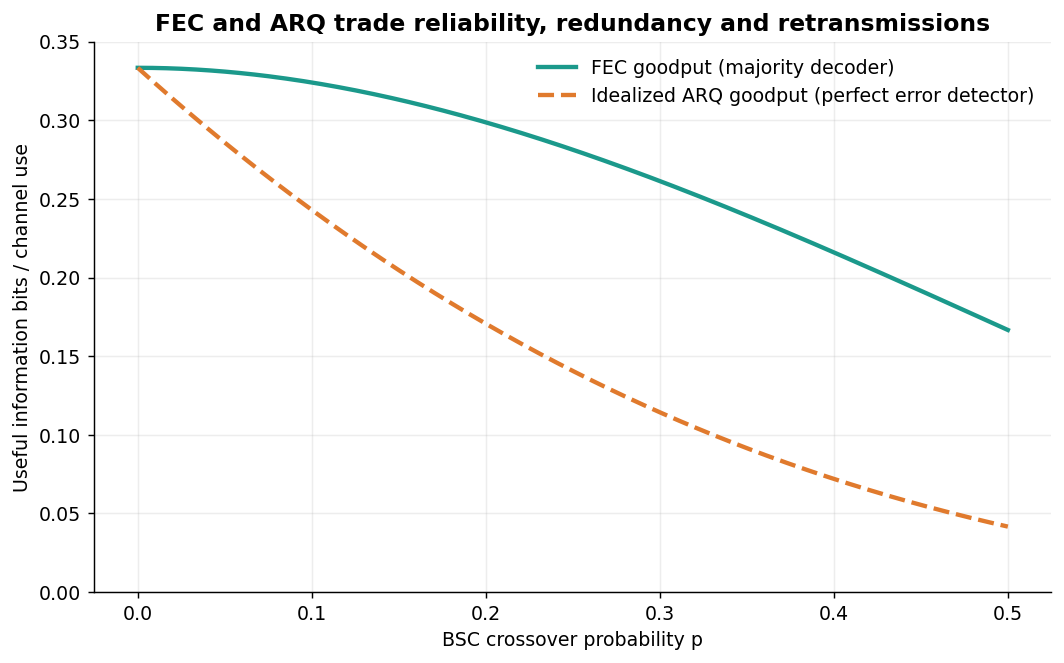

ARQ assumptions: ideal packet-error detection; no ACK/NACK overhead,
no round-trip delay, no feedback errors. Real ARQ throughput is lower.


In [17]:
p_arq = np.linspace(0, 0.5, 300)
p_fec_word_error = 3*p_arq**2 - 2*p_arq**3

# FEC: one information bit per 3 channel uses, successful if decoded correctly.
fec_goodput = R*(1-p_fec_word_error)

# Idealized ARQ: a packet attempt succeeds only if all three symbols are clean.
# Expected attempts = 1/(1-p)^3; goodput = one bit / expected channel uses.
arq_goodput = R*(1-p_arq)**3

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(p_arq, fec_goodput, color=TEAL, label="FEC goodput (majority decoder)")
ax.plot(p_arq, arq_goodput, color=ORANGE, linestyle="--",
        label="Idealized ARQ goodput (perfect error detector)")
ax.set_xlabel("BSC crossover probability p")
ax.set_ylabel("Useful information bits / channel use")
ax.set_title("FEC and ARQ trade reliability, redundancy and retransmissions")
ax.set_ylim(0, R*1.05)
ax.legend()
plt.show()

print("ARQ assumptions: ideal packet-error detection; no ACK/NACK overhead,")
print("no round-trip delay, no feedback errors. Real ARQ throughput is lower.")

## 14. Security connection: error correction is not authentication

The code's parity checks detect whether a received word is outside the code. But an intentional modification can map one valid codeword to another:
\[
000 \longrightarrow 111.
\]
The received word remains valid, so its syndrome is zero. The decoder has no evidence that the message was maliciously altered.

This is why error-control coding and cryptographic integrity solve different problems:
- error-control coding handles accidental corruption under a channel model;
- a message authentication code (MAC), such as HMAC, authenticates data using a secret key and detects unauthorized modification (assuming secure key management and a secure construction).

The HMAC example is educational and uses a temporary demonstration key; do not hard-code production secrets in notebooks or source repositories.

,Case,Received word,Syndrome,Passes code membership check?
0,Original,000,00,True
1,Random one-bit corruption,010,11,False
2,Intentional valid-codeword substitution,111,00,True


Original HMAC verifies: True
Tampered message verifies with the original tag: False


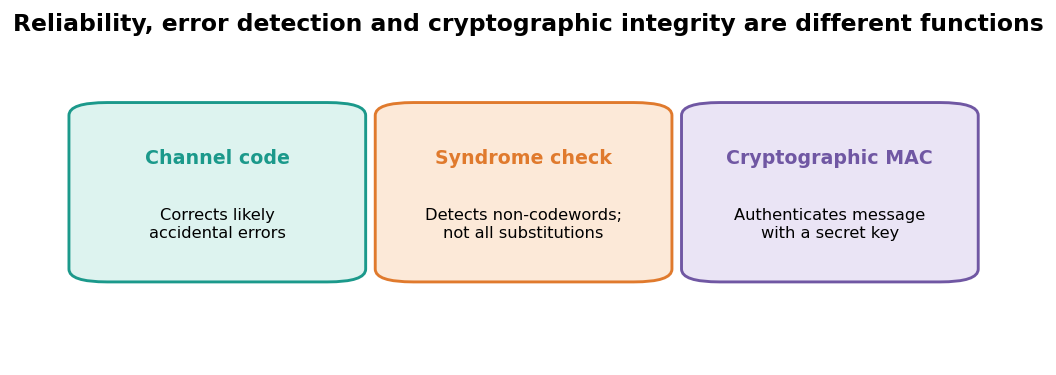

In [18]:
valid_original = np.array([0, 0, 0], dtype=np.int8)
randomly_corrupted = np.array([0, 1, 0], dtype=np.int8)
deliberately_modified = np.array([1, 1, 1], dtype=np.int8)

security_rows = []
for label, word in [
    ("Original", valid_original),
    ("Random one-bit corruption", randomly_corrupted),
    ("Intentional valid-codeword substitution", deliberately_modified)
]:
    s = syndrome(word)
    security_rows.append({
        "Case": label,
        "Received word": "".join(map(str, word)),
        "Syndrome": "".join(map(str, s)),
        "Passes code membership check?": not np.any(s)
    })
display(pd.DataFrame(security_rows))

demo_key = b"temporary-demo-key-do-not-use-in-production"
message = b"transfer=100;account=alice"
tag = hmac.new(demo_key, message, hashlib.sha256).hexdigest()
tampered_message = b"transfer=9000;account=alice"

valid_check = hmac.compare_digest(
    tag, hmac.new(demo_key, message, hashlib.sha256).hexdigest())
tampered_check = hmac.compare_digest(
    tag, hmac.new(demo_key, tampered_message, hashlib.sha256).hexdigest())

print("Original HMAC verifies:", valid_check)
print("Tampered message verifies with the original tag:", tampered_check)

fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.axis("off")
items = [
    (0.05, "Channel code", "Corrects likely\naccidental errors", "#DDF3EF", TEAL),
    (0.37, "Syndrome check", "Detects non-codewords;\nnot all substitutions", "#FCE9D8", ORANGE),
    (0.69, "Cryptographic MAC", "Authenticates message\nwith a secret key", "#EAE4F5", PURPLE)
]
for x, title, subtitle, face, edge in items:
    ax.add_patch(FancyBboxPatch(
        (x, 0.28), 0.25, 0.50,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=face, edgecolor=edge, linewidth=1.6))
    ax.text(x+0.125, 0.62, title, ha="center", weight="bold", color=edge)
    ax.text(x+0.125, 0.43, subtitle, ha="center", va="center", fontsize=9)
ax.set_title("Reliability, error detection and cryptographic integrity are different functions")
plt.show()

## 15. Interactive experiment: change channel conditions

Move the BSC crossover-probability slider and the AWGN \(E_b/N_0\) slider. The panels update the theoretical repetition-code error probability and compare the AWGN decoding strategies.

If controls do not render in a local Jupyter environment, run this notebook in Google Colab or enable `ipywidgets`.

The interactive widget is optional; all core plots and simulations run without it. If needed in a fresh Colab runtime, install it with `!pip -q install ipywidgets`.

In Colab, the widget cell attempts to enable Colab's custom widget manager automatically.

In [19]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    try:
        from google.colab import output as colab_output
        colab_output.enable_custom_widget_manager()
    except Exception:
        pass

    def interactive_lab(p=0.10, ebn0_db=3.0):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

        p_values = np.linspace(0.001, 0.5, 300)
        axes[0].plot(p_values, p_values, color=BLUE, label="Before decoding")
        axes[0].plot(p_values, 3*p_values**2-2*p_values**3,
                     color=TEAL, label="After ML decoding")
        after = 3*p**2 - 2*p**3
        axes[0].scatter([p, p], [p, after],
                        color=[BLUE, TEAL], s=65, zorder=5)
        axes[0].set_xlabel("BSC crossover p")
        axes[0].set_ylabel("Information-bit error probability")
        axes[0].set_title(f"BSC: p={p:.3f}, decoded={after:.5f}")
        axes[0].legend()

        dbs = np.linspace(-2, 10, 350)
        gammas = 10**(dbs/10)
        axes[1].semilogy(dbs, ber_uncoded_bpsk(gammas),
                         color=BLUE, label="Uncoded / soft ML")
        axes[1].semilogy(dbs, ber_repetition_hard(gammas),
                         color=ORANGE, linestyle="--", label="Hard majority")
        gamma_sel = 10**(ebn0_db/10)
        axes[1].axvline(ebn0_db, color=GRAY, linestyle=":")
        axes[1].scatter([ebn0_db, ebn0_db],
                        [ber_uncoded_bpsk(gamma_sel),
                         ber_repetition_hard(gamma_sel)],
                        color=[BLUE, ORANGE], s=60, zorder=5)
        axes[1].set_xlabel(r"$E_b/N_0$ (dB)")
        axes[1].set_ylabel("BER")
        axes[1].set_ylim(1e-7, 0.5)
        axes[1].set_title(f"AWGN: Eb/N0={ebn0_db:.1f} dB")
        axes[1].legend()

        plt.tight_layout()
        plt.show()
        print(f"BSC: before={p:.6f}, after={after:.6f}, improvement={p/after:.2f}x")
        print(f"AWGN: uncoded/soft-ML BER={float(ber_uncoded_bpsk(gamma_sel)):.4e}; "
              f"hard repetition BER={float(ber_repetition_hard(gamma_sel)):.4e}")

    controls = widgets.interactive(
        interactive_lab,
        p=widgets.FloatSlider(value=0.10, min=0.01, max=0.49, step=0.01,
                              description="BSC p", readout_format=".2f",
                              continuous_update=False),
        ebn0_db=widgets.FloatSlider(value=3.0, min=-2.0, max=10.0, step=0.5,
                                    description="Eb/N0 dB",
                                    continuous_update=False)
    )
    display(controls)

except Exception as exc:
    print("Optional interactive sliders were skipped because ipywidgets is not installed.")
    print("All analytical curves, simulations and visualizations above run without ipywidgets.")
    print("To enable sliders in Colab, run: !pip -q install ipywidgets")

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='BSC p', max=0.49, min=0.01,…

## 16. Reproducible conclusions

### What the experiments establish

1. The \((3,1)\) repetition code has rate \(1/3\), minimum distance 3, can correct one arbitrary bit error and can detect up to two errors.
2. On a BSC with \(p<1/2\), ML decoding is nearest-Hamming-neighbor decoding (majority vote).
3. The exact decoded information-bit error probability is \(3p^2-2p^3\), compared with \(p\) before decoding.
4. For a BEC, one surviving copy is enough; all three copies must be erased for the decoder to fail.
5. Soft ML and uncoded BPSK have identical BER at equal \(E_b/N_0\) for this particular repetition code. Hard decisions discard reliability information and perform worse.
6. The Shannon limit is a capacity threshold, not the BER curve of this short code.
7. Interleaving changes burst-error geometry; it does not change code rate.
8. A valid codeword can be maliciously substituted for another valid codeword. Error correction is not a substitute for a cryptographic MAC.

### Scope and limitations

This is a teaching laboratory, not a production communication or security implementation. The repetition code is intentionally inefficient. The ARQ comparison idealizes packet-error detection and ignores feedback overhead and delay. The HMAC example is demonstrative only. More advanced codes (Hamming, BCH, Reed–Solomon, convolutional, Turbo and LDPC) are natural next experiments, but belong to later chapters.

### References

- Shu Lin and Daniel J. Costello Jr., *Error Control Coding*, Chapter 1: Coding for Reliable Digital Transmission and Storage.
- C. E. Shannon, “A Mathematical Theory of Communication,” *Bell System Technical Journal*, 1948.